# Algorithm-choice coding bench: the source-data builder (`data.py`)

This notebook runs the code of `data.py`, the script that built the dataset artifact **Source data for an algorithm-choice coding bench**. The bench supports an interpretability study of which algorithm an LLM picks for a coding task (Dijkstra, BFS, quickselect, ...), and what it picks instead when that choice is banned in the prompt.

`data.py` standardises 10 external sources into one `exp_sel_data_out` file, `full_data_out.json` (61,469 examples, 96.2 MB). Each source row becomes `{input, output, metadata_*}`, grouped by dataset. The raw sources (1.4 GB, downloaded at pinned revisions) are not part of the published repository. So this demo runs the script on a **100-row subset of one source, LeetCodeDataset** (`newfacade/LeetCodeDataset`, Apache-2.0, Xia et al. 2025), loaded from `mini_demo_data.json`:
- all 20 LeetCode problems that `data.py` maps onto bench tasks, e.g. 743 *network delay time* → T02 weighted shortest path;
- 65 other train-split problems, spread over 22 algorithm-related topic tags and all three difficulties;
- 15 test-split problems, 5 per difficulty.

For the bench-mapped problems the script turns LeetCodeDataset into **hidden-test seeds**:
- it parses every recorded I/O pair into keyword arguments and an expected value, with a literal-only AST parser;
- it flags defective cases, such as expected outputs that are error messages;
- it re-runs the dataset's reference solution against its own `check()` in an isolated `python -I` subprocess with memory and CPU limits.

The code cells are `data.py` split into sections, with its original comments. Only what a notebook needs is changed, and each change is marked `notebook:`:
- `ROOT` is the working directory, since a notebook has no `__file__`.
- `load_rows()` and `sources_info()` read the demo data instead of `temp/datasets/` and `data_sources.json`. Their original code still runs when `USE_DEMO_DATA = False`.
- `main()` takes its options from the config cell instead of the command line.
- The output metadata leaves `data_py_sha256` empty.

The last cells compare the result with the full run's published values and plot it.

**Setup cells:** install the dependencies, import, and load `mini_demo_data.json` (from GitHub, or the local copy when offline).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# data.py is a uv inline script; its PEP 723 header pins what `uv run data.py` installs:
# /// script
# requires-python = ">=3.12,<3.13"
# dependencies = [
#     "loguru==0.7.3",
#     "tokenizers==0.23.3",
#     "huggingface-hub==2.2.0",
# ]
# ///

# loguru — NOT pre-installed on Colab, always install
_pip('loguru==0.7.3')

# Pre-installed on Colab, so installed locally only, at Colab's versions: tokenizers and huggingface_hub
# (data.py imports them lazily, for the noun bank's Qwen3 token counts), numpy, pandas and matplotlib (results cells)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
__doc__ = """Standardise the downloaded sources into one exp_sel_data_out file (full_data_out.json).

Every row of a source (or of its documented domain subset) becomes one example
{input, output, metadata_*}; examples are grouped by source dataset. Domain handling for the
algorithm-choice coding bench:

* LeetCode-derived rows are mapped to bench tasks (T01-T14, R1-R6). For the bench-mapped
  LeetCodeDataset problems every input_output pair is parsed into keyword arguments plus an
  expected value (case id leetcodedataset:<question_id>:<idx>), and the dataset's own reference
  solution is re-run against its check() in an isolated `python -I` subprocess.
* Implementations (TheAlgorithms, Mercury, XLCoST, KodCode, CLRS traces) carry the
  algorithm modes their path/title/question names (a text match, not a verified label) and, for
  TheAlgorithms, a hand-checked bench mode.
* llm-creativity states no licence: only program paths, the commit and the repository's judge
  labels are stored, never program text.
* The noun bank (Brysbaert concreteness norms) gets Qwen3 token counts and Open English WordNet
  noun classes, and flags candidates for neutral-twin / context-seed nouns.

Only the 10 datasets chosen in the selection stage are built (reasons in README.md and
DATASET_SELECTION.md); scripts/selection_stage_data_all15.py is the 15-source version that was run to
make that choice.

Run:  uv run data.py                                   # all 10 chosen datasets -> full_data_out.json
      uv run data.py --datasets leetcodedataset,mercury # a subset (written to --out)
"""
# ^ data.py's module docstring; main() uses its first line as the argparse description

import argparse
import ast
import functools
import hashlib
import json
import re
import resource
import subprocess
import sys
import time
import warnings
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

from loguru import logger

# Notebook additions: fnmatch matches load_rows() glob patterns against the demo data's file paths;
# matplotlib and pandas draw the results.
import fnmatch

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-1/dataset-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["selection"])
for path, rows in data["source_files"].items():
    print(f"temp/datasets/{path}: {len(rows)} rows")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
all 20 bench-mapped problems present (train split); 65 other train problems, one per (topic tag, difficulty) slot, round-robin over 22 algorithm-related tags, rows <= 60 KB; 15 test problems, 5 per difficulty; random.Random(0); rows keep their source order
temp/datasets/leetcodedataset/full_newfacade_LeetCodeDataset_default_train.json: 85 rows
temp/datasets/leetcodedataset/full_newfacade_LeetCodeDataset_default_test.json: 15 rows


## Configuration

The first five settings are `data.py`'s command-line options (`--datasets`, `--out`, `--clrs-per-length`, `--no-verify`, `--max-mb`). `main()` passes them to its own `argparse` parser.

The last two control the demo:
- `USE_DEMO_DATA` makes `load_rows()` and `sources_info()` read the loaded `mini_demo_data.json` instead of `temp/datasets/` and `data_sources.json`.
- `MAX_ROWS_PER_FILE` caps how many rows each source file contributes.

The demo builds only `leetcodedataset`, the one source in the demo data.

**Full original run.** Run the notebook from a clone of the dataset repository after `bash restore.sh` has re-downloaded the pinned sources into `temp/datasets/`, with these settings:
- `USE_DEMO_DATA = False`
- `DATASETS = "all"`
- `OUT = "full_data_out.json"`

That builds all 10 datasets, 61,469 examples, exactly as `uv run data.py` does. In the original run's log, the LeetCodeDataset builder took about 2 s for its 2,869 rows and 20 reference checks, and the 10 builders about 25 s together.

In [5]:
# data.py's command-line options; each comment gives the option and its default (the full original run)
DATASETS = "leetcodedataset"   # --datasets: default "all" (the 10 chosen datasets); the demo data holds leetcodedataset rows only
OUT = "demo_data_out.json"     # --out: default ROOT / "full_data_out.json"
CLRS_PER_LENGTH = 5            # --clrs-per-length: default 5 (read by the clrs_text builder only)
NO_VERIFY = False              # --no-verify: default False, i.e. re-run each bench-mapped reference solution against check()
MAX_MB = 95.0                  # --max-mb: default 95.0; a larger output is split into numbered parts

# Demo settings (not in data.py)
USE_DEMO_DATA = True           # False: load_rows()/sources_info() read temp/datasets/ and data_sources.json, as data.py does
MAX_ROWS_PER_FILE = None       # rows taken from each demo source file; None = all of them (85 train + 15 test).
                               # The full source files have 2,641 train + 228 test rows.

## Setup: paths and logging

`data.py` resolves everything against its own folder, the repository root:
- raw downloads under `temp/datasets/`;
- logs under `logs/`, with INFO going to stdout and DEBUG to `logs/data.log`.

In the notebook the working directory takes the place of the repository root.

In [6]:
ROOT = Path.cwd()  # notebook: data.py has ROOT = Path(__file__).resolve().parent, the repository root
DATA = ROOT / "temp" / "datasets"
LOG_DIR = ROOT / "logs"
LOG_DIR.mkdir(exist_ok=True)

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(LOG_DIR / "data.log", rotation="30 MB", level="DEBUG")

2

## Bench vocabulary: tasks and the LeetCode map

The bench has 18 tasks: T01–T14 and R1, R2, R3, R6. Each asks for one function that several algorithms can implement, for example T02 `find_path(graph, start, goal)` (Dijkstra, Bellman-Ford, A*, ...) or T03 *k-th smallest* (quickselect, heap, sorting, ...).

`LEETCODE_BENCH_MAP` names the LeetCode problems whose recorded I/O pairs seed each task's hidden tests:
- **primary seeds**: the problems named in the plan;
- **alternates**: e.g. 1631 and 1514 for T02;
- **related**: 1091, for T01.

146 (T09, LRU cache) and 295 (T12, streaming median) are mapped but absent from LeetCodeDataset, so their tests must be generated.

`LEETCODE_ANSWER_SEMANTICS` records what each problem's expected output means, because many differ from the bench task. For example, 743 returns the largest shortest-path distance rather than a path, and 215 asks for the k-th *largest*. The bench build uses these notes to convert the cases.

`ERROR_OUTPUT_RE` recognises a dataset defect: an expected output that is a runtime error message.

In [7]:
# ---------------------------------------------------------------------------------------------
# Bench vocabulary (task ids follow the artifact plan; mode ids are this script's vocabulary,
# to be mapped onto the frozen catalogues when the task specs are written).
# ---------------------------------------------------------------------------------------------
BENCH_TASKS = {
    "T01_grid_path": "4-neighbour grid path, any valid path",
    "T02_weighted_shortest_path": "find_path(graph, start, goal), integer weights 1..100, any optimal path",
    "T03_kth_smallest": "k-th smallest of nums",
    "T04_substring_search": "first index of pattern in text without built-in search",
    "T05_two_sum": "indices (i, j), i < j, summing to target",
    "T06_find_duplicate": "the repeated value among n+1 values in 1..n",
    "T07_convex_hull": "strict hull vertices counter-clockwise",
    "T08_fibonacci": "exact F(n), 0 <= n <= 500",
    "T09_lru_cache": "LRUCache(capacity) with get/put",
    "T10_connected_components": "number of components of an undirected graph",
    "T11_longest_increasing_subsequence": "length of the longest strictly increasing subsequence",
    "T12_streaming_median": "median after each insertion",
    "T13_merge_intervals": "merge overlapping intervals",
    "T14_top_k_frequent": "k most frequent values, order free",
    "R1_interval_scheduling": "maximum set of non-overlapping intervals",
    "R2_redundant_connection": "edge whose removal leaves a tree",
    "R3_course_schedule": "any topological order or []",
    "R6_first_occurrence": "first index of target in a sorted array",
}

# LeetCode question id -> (bench task, role). Primary seeds are the problems named in the plan.
LEETCODE_BENCH_MAP: dict[int, tuple[str, str]] = {
    743: ("T02_weighted_shortest_path", "primary_seed"),
    215: ("T03_kth_smallest", "primary_seed"),
    28: ("T04_substring_search", "primary_seed"),
    1: ("T05_two_sum", "primary_seed"),
    287: ("T06_find_duplicate", "primary_seed"),
    587: ("T07_convex_hull", "primary_seed"),
    509: ("T08_fibonacci", "primary_seed"),
    146: ("T09_lru_cache", "primary_seed"),
    547: ("T10_connected_components", "primary_seed"),
    323: ("T10_connected_components", "alternate_seed_exact_signature"),
    300: ("T11_longest_increasing_subsequence", "primary_seed"),
    295: ("T12_streaming_median", "primary_seed"),
    56: ("T13_merge_intervals", "primary_seed"),
    347: ("T14_top_k_frequent", "primary_seed"),
    435: ("R1_interval_scheduling", "primary_seed"),
    684: ("R2_redundant_connection", "primary_seed"),
    210: ("R3_course_schedule", "primary_seed"),
    34: ("R6_first_occurrence", "primary_seed"),
    1971: ("T10_connected_components", "alternate_seed"),
    1631: ("T02_weighted_shortest_path", "alternate_seed"),
    1514: ("T02_weighted_shortest_path", "alternate_seed"),
    1091: ("T01_grid_path", "related_not_reused_8_directional"),
}

# What a LeetCode expected output means for each bench-mapped problem (the bench build converts these).
LEETCODE_ANSWER_SEMANTICS: dict[int, str] = {
    743: "scalar: max over nodes of the shortest distance from k, -1 if any node is unreachable; T02 recomputes a path per (start, goal)",
    215: "scalar: k-th largest; T03 uses k' = n - k + 1 for k-th smallest",
    28: "scalar: first index of needle in haystack or -1",
    1: "pair of indices; LeetCode accepts either order; some generated cases have no solution (expected null), which T05's spec excludes",
    287: "scalar: the duplicated value",
    587: "list of fence points including collinear boundary points, any order; T07 recomputes the strict counter-clockwise hull",
    509: "scalar: F(n) for n <= 30",
    547: "scalar: number of provinces from an adjacency matrix",
    323: "scalar: number of components from (n, edges)",
    300: "scalar: length of the longest strictly increasing subsequence",
    56: "list of merged intervals sorted by start",
    347: "list of the k most frequent values, any order",
    435: "scalar: minimum number of removals; R1 converts to the maximum non-overlapping set",
    684: "edge [u, v]: the last edge in input order that closes a cycle",
    210: "any valid topological order, [] if impossible; expected shows one valid order",
    34: "[first, last] indices of target or [-1, -1]; R6 uses the first",
    1971: "bool: destination reachable from source",
    1631: "scalar: minimum effort (max absolute height step) of a top-left to bottom-right path",
    1514: "float: maximum success probability of a start-to-end path",
    1091: "scalar: shortest 8-directional clear path length or -1",
}
ERROR_OUTPUT_RE = re.compile(r"^\s*(Error|Exception|Traceback)\b", re.I)

## Algorithm-mode lexicon

The other sources do not say which algorithm a program implements, so `data.py` derives *hints* from names, titles and questions.

- `MODE_LEXICON` maps each mode id (e.g. `dijkstra`, `kmp`, `quickselect`) to the bench tasks it can solve and to a regex.
- `LEXICON_EXCLUDE` suppresses homonyms: Boyer–Moore *majority vote* is not the string search, and regex or wildcard matching is not pattern search.

The matches fill `metadata_named_algorithms`, which the README calls "hints, not verified labels". The LeetCodeDataset builder does not use the lexicon, but `main()` writes it into the output metadata.

In [8]:
# Text lexicon: mode id, bench tasks it belongs to, regex over lower-cased names/titles/questions.
MODE_LEXICON: list[tuple[str, tuple[str, ...], str]] = [
    ("dijkstra", ("T02_weighted_shortest_path", "T01_grid_path"), r"dijkstra|uniform[\s_-]*cost"),
    ("bellman_ford_spfa", ("T02_weighted_shortest_path",), r"bellman[\s_-]*ford|\bspfa\b|shortest path faster"),
    ("floyd_warshall", ("T02_weighted_shortest_path",), r"floyd[\s_-]*warshall|warshall"),
    ("a_star", ("T01_grid_path", "T02_weighted_shortest_path"), r"\ba\*[\s_-]*(search|algorithm|path)|\ba[\s-]star[\s-]*(search|algorithm|path)|\ba_star\b|\bastar\b"),
    ("bidirectional_search", ("T01_grid_path", "T02_weighted_shortest_path"), r"bi[\s_-]?directional[\s_-]*(search|bfs|breadth|dijkstra|a\*|a[\s_-]?star|astar)"),
    ("zero_one_bfs", ("T02_weighted_shortest_path",), r"\b0[\s_-]?1[\s_-]?bfs|zero[\s_-]one[\s_-]bfs"),
    ("dial", ("T02_weighted_shortest_path",), r"\bdial'?s?[\s_-]*algorithm|bucket[\s_-]*queue"),
    ("bfs", ("T01_grid_path", "T10_connected_components", "R3_course_schedule"), r"breadth[\s_-]*first|\bbfs\b"),
    ("dfs", ("T01_grid_path", "T10_connected_components", "R2_redundant_connection", "R3_course_schedule"), r"depth[\s_-]*first|\bdfs\b"),
    ("topological_sort", ("R3_course_schedule",), r"topolog|\bkahn"),
    ("union_find", ("T10_connected_components", "R2_redundant_connection"), r"union[\s_-]*find|disjoint[\s_-]*set|\bdsu\b"),
    ("kruskal", ("T10_connected_components", "R2_redundant_connection"), r"kruskal"),
    ("connected_components", ("T10_connected_components",), r"connected[\s_-]*component"),
    ("quickselect", ("T03_kth_smallest", "T14_top_k_frequent"), r"quick[\s_-]?select|hoare'?s selection|kth[\s_-]order[\s_-]statistic"),
    ("median_of_medians", ("T03_kth_smallest",), r"median[\s_-]*of[\s_-]*medians"),
    ("kth_smallest_largest", ("T03_kth_smallest",), r"\bk[\s_-]?th[\s_-]+(smallest|largest)|kth[\s_-](smallest|largest)"),
    ("counting_sort", ("T03_kth_smallest",), r"counting[\s_-]*sort"),
    ("heap", ("T03_kth_smallest", "T12_streaming_median", "T14_top_k_frequent"), r"\bheap|priority[\s_-]*queue|heapq"),
    ("naive_string_search", ("T04_substring_search",), r"naive[\s_-]*(string|pattern)|brute[\s_-]*force[\s_-]*(string|pattern)"),
    ("kmp", ("T04_substring_search",), r"knuth[\s_-]*morris|morris[\s_-]*pratt|\bkmp\b|prefix[\s_-]*function|failure[\s_-]*function"),
    ("rabin_karp", ("T04_substring_search",), r"rabin[\s_-]*karp|rolling[\s_-]*hash"),
    ("boyer_moore", ("T04_substring_search",), r"boyer[\s_-]*moore|horspool"),
    ("z_algorithm", ("T04_substring_search",), r"\bz[\s_-]*(algorithm|function|array)\b"),
    ("pattern_search", ("T04_substring_search",), r"pattern[\s_-]*search|substring[\s_-]*search|string[\s_-]*search|find[\s_-]*(all[\s_-]*)?occurrences[\s_-]*of[\s_-]*(a[\s_-]*|the[\s_-]*)?pattern"),
    ("two_sum", ("T05_two_sum",), r"two[\s_-]*sum|pair[\s_-]*(with|whose)[\s_-]*(given[\s_-]*)?sum"),
    ("floyd_cycle_detection", ("T06_find_duplicate",), r"tortoise|floyd'?s?[\s_-]*cycle"),
    ("find_duplicate", ("T06_find_duplicate",), r"find[\s_-]*(the[\s_-]*|a[\s_-]*|all[\s_-]*)?duplicates?\b|duplicate[\s_-]*number"),
    ("graham_scan", ("T07_convex_hull",), r"graham"),
    ("jarvis_march", ("T07_convex_hull",), r"jarvis|gift[\s_-]*wrap"),
    ("monotone_chain", ("T07_convex_hull",), r"monotone[\s_-]*chain|andrew'?s"),
    ("quickhull", ("T07_convex_hull",), r"quick[\s_-]*hull"),
    ("convex_hull", ("T07_convex_hull",), r"convex[\s_-]*hull"),
    ("fibonacci_matrix_power", ("T08_fibonacci",), r"fibonacci.*matrix|matrix.*fibonacci"),
    ("fibonacci_fast_doubling", ("T08_fibonacci",), r"fast[\s_-]*doubling|doubling.*fibonacci|fast[\s_-]*fibonacci"),
    ("fibonacci_closed_form", ("T08_fibonacci",), r"binet|golden[\s_-]*ratio|analytic[\s_-]*fibonacci"),
    ("fibonacci", ("T08_fibonacci",), r"fibonacci"),
    ("lru_cache", ("T09_lru_cache",), r"\blru\b|least[\s_-]*recently[\s_-]*used"),
    ("lis_n_log_n", ("T11_longest_increasing_subsequence",), r"(longest[\s_-]*increasing[\s_-]*subsequence|\blis\b).*(n[\s_]?log|o_nlogn|binary[\s_-]*search|patience)|patience[\s_-]*sort"),
    ("lis", ("T11_longest_increasing_subsequence",), r"longest[\s_-]*increasing[\s_-]*subsequence|\blis\b"),
    ("running_median", ("T12_streaming_median",), r"running[\s_-]*median|median.*(data[\s_-]*)?stream|median[\s_-]*finder|two[\s_-]*heaps"),
    ("merge_intervals", ("T13_merge_intervals",), r"merge[\s_-]*(overlapping[\s_-]*)?intervals|overlapping[\s_-]*intervals"),
    ("top_k_frequent", ("T14_top_k_frequent",), r"top[\s_-]*k\b|k[\s_-]*most[\s_-]*frequent"),
    ("bucket_sort", ("T14_top_k_frequent",), r"bucket[\s_-]*sort"),
    ("activity_selection", ("R1_interval_scheduling",), r"activity[\s_-]*select|interval[\s_-]*scheduling|non[\s_-]*overlapping[\s_-]*intervals"),
    ("binary_search", ("R6_first_occurrence", "T11_longest_increasing_subsequence"), r"binary[\s_-]*search(?![\s_-]*tree)|bisect"),
    ("exponential_search", ("R6_first_occurrence",), r"exponential[\s_-]*search|galloping"),
]
# A mode is not reported when its exclusion pattern also matches (homonymous algorithms).
LEXICON_EXCLUDE: dict[str, str] = {
    "boyer_moore": r"majority|voting|\bvote\b",
    "pattern_search": r"regular[\s_-]*expression|wildcard",
}
_LEXICON = [(m, t, re.compile(p)) for m, t, p in MODE_LEXICON]
_EXCLUDE = {m: re.compile(p) for m, p in LEXICON_EXCLUDE.items()}

## Hand-checked labels and cross-source links

These constants serve the builders of the other sources and are kept because they are part of `data.py`:
- `THEALGORITHMS_CURATED`: 55 TheAlgorithms/Python files, read by hand and labelled with (bench task, mode).
- `CLRS_LINKS`: the CLRS-30 algorithms whose execution traces exercise a bench mode.
- `LLM_CREATIVITY_T02`: maps the blind-judge lineage labels of the llm-creativity repository's `find_path` programs onto T02 modes. BFS, DFS and beam search count as `other`.
- `FINGERPRINT_AXES`: that repository's 11 fingerprint axes.

In [9]:
# Hand-checked TheAlgorithms files -> (bench task, mode). Read in this step; see README.md.
THEALGORITHMS_CURATED: dict[str, tuple[str, str]] = {
    "graphs/dijkstra.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_2.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_algorithm.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_alternate.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_binary_grid.py": ("T01_grid_path", "dijkstra"),
    "graphs/bellman_ford.py": ("T02_weighted_shortest_path", "bellman_ford_spfa"),
    "graphs/graphs_floyd_warshall.py": ("T02_weighted_shortest_path", "floyd_warshall"),
    "dynamic_programming/floyd_warshall.py": ("T02_weighted_shortest_path", "floyd_warshall"),
    "graphs/bi_directional_dijkstra.py": ("T02_weighted_shortest_path", "bidirectional_search"),
    "graphs/breadth_first_search_zero_one_shortest_path.py": ("T02_weighted_shortest_path", "zero_one_bfs"),
    "graphs/a_star.py": ("T01_grid_path", "a_star"),
    "graphs/bidirectional_a_star.py": ("T01_grid_path", "bidirectional_search"),
    "graphs/bidirectional_breadth_first_search.py": ("T01_grid_path", "bidirectional_search"),
    "graphs/breadth_first_search_shortest_path.py": ("T01_grid_path", "bfs"),
    "graphs/breadth_first_search_shortest_path_2.py": ("T01_grid_path", "bfs"),
    "graphs/breadth_first_search.py": ("T10_connected_components", "bfs"),
    "graphs/breadth_first_search_2.py": ("T10_connected_components", "bfs"),
    "graphs/depth_first_search.py": ("T10_connected_components", "dfs"),
    "graphs/depth_first_search_2.py": ("T10_connected_components", "dfs"),
    "graphs/connected_components.py": ("T10_connected_components", "dfs"),
    "data_structures/disjoint_set/disjoint_set.py": ("T10_connected_components", "union_find"),
    "data_structures/disjoint_set/alternate_disjoint_set.py": ("T10_connected_components", "union_find"),
    "graphs/g_topological_sort.py": ("R3_course_schedule", "topological_sort"),
    "searches/quick_select.py": ("T03_kth_smallest", "quickselect"),
    "divide_and_conquer/kth_order_statistic.py": ("T03_kth_smallest", "quickselect"),
    "data_structures/arrays/kth_largest_element.py": ("T03_kth_smallest", "quickselect"),
    "searches/median_of_medians.py": ("T03_kth_smallest", "median_of_medians"),
    "sorts/counting_sort.py": ("T03_kth_smallest", "counting_sort"),
    "strings/naive_string_search.py": ("T04_substring_search", "naive_string_search"),
    "strings/knuth_morris_pratt.py": ("T04_substring_search", "kmp"),
    "strings/prefix_function.py": ("T04_substring_search", "kmp"),
    "strings/rabin_karp.py": ("T04_substring_search", "rabin_karp"),
    "strings/boyer_moore_search.py": ("T04_substring_search", "boyer_moore"),
    "strings/boyer_moore_horspool.py": ("T04_substring_search", "boyer_moore"),
    "strings/z_function.py": ("T04_substring_search", "z_algorithm"),
    "maths/two_sum.py": ("T05_two_sum", "two_sum_hash_map"),
    "data_structures/linked_list/floyds_cycle_detection.py": ("T06_find_duplicate", "floyd_cycle_detection"),
    "geometry/graham_scan.py": ("T07_convex_hull", "graham_scan"),
    "other/graham_scan.py": ("T07_convex_hull", "graham_scan"),
    "geometry/jarvis_march.py": ("T07_convex_hull", "jarvis_march"),
    "divide_and_conquer/convex_hull.py": ("T07_convex_hull", "divide_and_conquer_hull"),
    "maths/fibonacci.py": ("T08_fibonacci", "fibonacci_several_variants"),
    "dynamic_programming/fibonacci.py": ("T08_fibonacci", "fibonacci_iteration_table"),
    "dynamic_programming/fast_fibonacci.py": ("T08_fibonacci", "fibonacci_fast_doubling"),
    "matrix/nth_fibonacci_using_matrix_exponentiation.py": ("T08_fibonacci", "fibonacci_matrix_power"),
    "other/lru_cache.py": ("T09_lru_cache", "dict_doubly_linked_list"),
    "dynamic_programming/longest_increasing_subsequence.py": ("T11_longest_increasing_subsequence", "lis_recursive"),
    "dynamic_programming/longest_increasing_subsequence_iterative.py": ("T11_longest_increasing_subsequence", "lis_dp_quadratic"),
    "dynamic_programming/longest_increasing_subsequence_o_nlogn.py": ("T11_longest_increasing_subsequence", "lis_n_log_n"),
    "data_structures/arrays/merge_intervals.py": ("T13_merge_intervals", "sort_and_sweep"),
    "greedy_methods/activity_selection.py": ("R1_interval_scheduling", "activity_selection"),
    "other/activity_selection.py": ("R1_interval_scheduling", "activity_selection"),
    "searches/binary_search.py": ("R6_first_occurrence", "binary_search"),
    "searches/simple_binary_search.py": ("R6_first_occurrence", "binary_search"),
    "searches/exponential_search.py": ("R6_first_occurrence", "exponential_search"),
}

# CLRS-30 algorithms that implement a bench mode -> links "task:mode".
CLRS_LINKS: dict[str, list[str]] = {
    "bfs": ["T01_grid_path:bfs", "T10_connected_components:bfs"],
    "dfs": ["T01_grid_path:dfs", "T10_connected_components:dfs"],
    "dijkstra": ["T02_weighted_shortest_path:dijkstra"],
    "bellman_ford": ["T02_weighted_shortest_path:bellman_ford_spfa"],
    "floyd_warshall": ["T02_weighted_shortest_path:floyd_warshall"],
    "dag_shortest_paths": ["T02_weighted_shortest_path:dag_dp"],
    "topological_sort": ["R3_course_schedule:topological_sort"],
    "mst_kruskal": ["T10_connected_components:union_find", "R2_redundant_connection:union_find"],
    "quickselect": ["T03_kth_smallest:quickselect"],
    "naive_string_matcher": ["T04_substring_search:naive_string_search"],
    "kmp_matcher": ["T04_substring_search:kmp"],
    "graham_scan": ["T07_convex_hull:graham_scan"],
    "jarvis_march": ["T07_convex_hull:jarvis_march"],
    "activity_selector": ["R1_interval_scheduling:activity_selection"],
    "binary_search": ["R6_first_occurrence:binary_search"],
}

# llm-creativity judge lineage (lineage_minor) -> T02 mode. The plan maps BFS, DFS and beam search to 'other'.
LLM_CREATIVITY_T02: dict[str, tuple[str, str]] = {
    "dijkstra": ("dijkstra", "dijkstra"),
    "uniform_cost": ("dijkstra", "uniform_cost"),
    "bidirectional_dijkstra": ("bidirectional_search", "bidirectional_dijkstra"),
    "bellman_ford": ("bellman_ford_spfa", "bellman_ford"),
    "spfa": ("bellman_ford_spfa", "spfa"),
    "floyd_warshall": ("floyd_warshall", "floyd_warshall"),
    "dial_bucket": ("dial", "dial_bucket"),
    "astar": ("a_star", "astar"),
    "greedy_best_first": ("a_star", "greedy_best_first"),
    "bidirectional_astar": ("bidirectional_search", "bidirectional_astar"),
    "bfs": ("other", "bfs"),
    "bidirectional_bfs": ("other", "bidirectional_bfs"),
    "dfs": ("other", "dfs"),
    "beam": ("other", "beam"),
    "random_walk_traversal": ("other", "random_walk_traversal"),
    "hybrid": ("other", "hybrid"),
}
FINGERPRINT_AXES = ("trajectory", "stochasticity", "coverage", "heuristic", "frontier", "state_scope",
                    "backtracking", "memory", "adaptation", "topology", "learning")

## Structural code markers and noun-bank filters

- `CODE_MARKERS` are regexes over the code of Mercury's human solutions (heapq, sort, bisect, OrderedDict, ...), a hint for labellers.
- `IO_HACK_RE` flags solutions that game the judge through stdout or stdin.

The three word sets filter the concreteness noun bank, whose neutral nouns go into the neutral-twin and context-seed prompts:
- `CONCRETE_LEXFILES`: the WordNet noun classes that count as concrete; a word needs at least one.
- `CS_TERMS`: programming words, which would not be neutral next to a coding task.
- `SENSITIVE_TERMS`: words unsuitable for prompts.

In [10]:
# Structural markers (regex over code) reported for human solutions; a hint for labellers, not a label.
CODE_MARKERS = {
    "heapq": r"\bheap(push|pop|ify|replace|pushpop)\b|\bnsmallest\b|\bnlargest\b",
    "sort": r"\bsorted\(|\.sort\(",
    "bisect": r"\bbisect\w*\(|\binsort\w*\(",
    "ordered_dict": r"OrderedDict|move_to_end",
    "deque": r"\bdeque\(",
    "counter": r"\bCounter\(",
    "linked_nodes": r"\.prev\b|\.next\b",
    "recursion_cache": r"@(functools\.)?(lru_)?cache\b",
    "set": r"\bset\(\)|\bset\(",
    "two_pointers": r"\bwhile\s+\w+\s*<\s*\w+\s*:",
}
IO_HACK_RE = re.compile(r"sys\.stdout|open\(\s*['\"]user\.out|\bstdin\b|atexit")

# Neutral-noun bank filters for concreteness_nouns.
CONCRETE_LEXFILES = {"noun.artifact", "noun.animal", "noun.plant", "noun.food", "noun.object", "noun.substance"}
CS_TERMS = {  # data-structure / programming words, which would not be neutral next to a coding task
    "tree", "graph", "heap", "stack", "queue", "list", "array", "map", "set", "table", "node", "path", "key",
    "bucket", "pointer", "matrix", "string", "window", "hash", "grid", "edge", "vertex", "link", "chain", "net",
    "network", "file", "record", "cell", "block", "index", "code", "program", "computer", "keyboard", "mouse",
    "screen", "disk", "bit", "byte", "bridge", "root", "leaf", "branch", "cache", "web", "pipe", "port", "socket",
    "frame", "box", "ladder", "wheel", "lock", "token", "number", "letter", "word", "page", "book", "card", "deck",
    "dial", "python", "java", "ruby", "perl", "pearl", "cookie", "bug", "virus", "worm", "shell", "server", "client",
    "terminal", "cloud", "log", "thread", "trunk", "chip", "chips", "cable", "wire", "router", "monitor", "printer",
    "laptop", "tablet", "robot", "bot", "spider", "crawler", "sandbox", "pipeline", "console", "memory", "register",
    "folder", "compass", "anchor", "badge", "label", "tag", "rope", "knot", "line", "corner", "basket",
}
SENSITIVE_TERMS = {
    "breast", "breasts", "penis", "vagina", "nipple", "nipples", "condom", "tampon", "bra", "panties", "underwear",
    "bikini", "butt", "buttocks", "testicle", "testicles", "semen", "sperm", "urine", "feces", "poop", "vomit", "diaper",
    "toilet", "gun", "rifle", "pistol", "bullet", "bomb", "grenade", "knife", "dagger", "sword", "noose", "coffin",
    "corpse", "skull", "syringe", "needle", "cigarette", "cigar", "joint", "beer", "whiskey", "vodka", "wine", "liquor",
    "booze", "cocaine", "heroin", "marijuana", "blood", "wound", "tumor", "cancer", "nazi", "slave", "whip",
    "whisky", "rum", "gin", "tequila", "lager", "champagne", "brandy", "cocktail", "pills", "pill", "drugs", "weed",
    "bra", "lingerie", "thong", "jail", "prison", "cage", "handcuffs", "chain", "grave", "tombstone", "casket",
}

## Helpers: loading source rows and matching the lexicon

`load_rows(pattern)` loads every source file that matches a glob under `temp/datasets/` and concatenates their rows. Files are taken in natural order, so `_2` comes before `_10`.

The notebook adds one branch at the top: with `USE_DEMO_DATA`, it matches the same pattern against the file paths stored in `data["source_files"]` and takes at most `MAX_ROWS_PER_FILE` rows from each. The original disk-reading code below that branch is unchanged.

- `named_modes` and `tasks_of` apply the lexicon.
- `parses_py312` reports whether code parses under Python 3.12, with the `SyntaxWarning`s from invalid escapes in third-party code silenced.

In [11]:
# ---------------------------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------------------------
def load_rows(pattern: str) -> list[dict]:
    """Load full_*.json files (and split parts) matching a glob under temp/datasets, in natural order."""
    if USE_DEMO_DATA:  # notebook: the files come from mini_demo_data.json, keyed by their path under temp/datasets
        files = sorted((k for k in data["source_files"] if fnmatch.fnmatch(k, pattern)),
                       key=lambda p: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", Path(p).name)])
        if not files:
            raise FileNotFoundError(f"no files match temp/datasets/{pattern} in the demo data, which holds {sorted(data['source_files'])}")
        return [r for f in files for r in data["source_files"][f][:MAX_ROWS_PER_FILE]]
    files = sorted(DATA.glob(pattern), key=lambda p: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", p.name)])
    files = [f for f in files if f.is_file()]
    if not files:
        raise FileNotFoundError(f"no files match temp/datasets/{pattern}; run scripts/download_all.py")
    rows: list[dict] = []
    for f in files:
        rows.extend(json.loads(f.read_text()))
    return rows


def named_modes(text: str) -> list[str]:
    t = text.lower()
    return [m for m, _, rx in _LEXICON if rx.search(t) and not (m in _EXCLUDE and _EXCLUDE[m].search(t))]


def tasks_of(modes: list[str]) -> list[str]:
    tasks = {t for m, ts, _ in _LEXICON if m in modes for t in ts}
    return sorted(tasks)


def parse_quietly(code: str) -> ast.Module:
    """ast.parse without the SyntaxWarnings that third-party code with invalid escapes emits."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", SyntaxWarning)
        return ast.parse(code)


def parses_py312(code: str) -> bool:
    try:
        parse_quietly(code)
        return True
    except (SyntaxError, ValueError):
        return False

## Parsing LeetCode I/O strings without executing them

LeetCodeDataset stores each test case as two strings, for example `input = "nums = [3,3], target = 6"` and `output = "[0, 1]"`.

- `parse_kwargs` wraps the input as the call `f(nums = [3,3], target = 6)`, parses it with `ast` and converts each keyword value with `literal`.
- `parse_value` does the same for the output.
- `literal` accepts only constants, lists/tuples/sets, dicts, signed numbers and the names `true`/`false`/`null`/`True`/`False`/`None`.

Anything else raises `ValueError`, and the builder records the case as `unparseable` instead of evaluating it.

In [12]:
_NAMES = {"true": True, "false": False, "null": None, "True": True, "False": False, "None": None}


def literal(node: ast.AST) -> object:
    """Convert a literal-only AST node; accepts JSON spellings true/false/null. Raises ValueError otherwise."""
    if isinstance(node, ast.Constant):
        return node.value
    if isinstance(node, (ast.List, ast.Tuple, ast.Set)):
        return [literal(e) for e in node.elts]
    if isinstance(node, ast.Dict):
        return {literal(k): literal(v) for k, v in zip(node.keys, node.values)}
    if isinstance(node, ast.UnaryOp) and isinstance(node.op, (ast.USub, ast.UAdd)):
        v = literal(node.operand)
        if not isinstance(v, (int, float)):
            raise ValueError("unary op on non-number")
        return -v if isinstance(node.op, ast.USub) else v
    if isinstance(node, ast.Name) and node.id in _NAMES:
        return _NAMES[node.id]
    raise ValueError(f"non-literal node {type(node).__name__}")


def parse_kwargs(s: str) -> dict:
    call = ast.parse(f"f({s})", mode="eval").body
    if not isinstance(call, ast.Call) or call.args:
        raise ValueError("input is not keyword-only")
    return {kw.arg: literal(kw.value) for kw in call.keywords}


def parse_value(s: str) -> object:
    return literal(ast.parse(s.strip(), mode="eval").body)

## Re-running reference solutions in a sandbox

`run_reference_check` runs a generated script with `python -I`. Isolated mode ignores the `PYTHON*` environment variables and leaves the script's folder off `sys.path`. Limits:
- `_limits` caps the child at 2 GB of address space and 60 s of CPU before it starts;
- the parent adds a 90 s wall-clock timeout.

A check passes only if the script exits with code 0 and its output ends with `ALL_OK`.

- `rel` keeps absolute server paths out of logs and metadata.
- `sources_info` returns the pinned source records. In the notebook (with `USE_DEMO_DATA`) they come from the demo data; otherwise from `data_sources.json`.

In [13]:
def _limits() -> None:
    resource.setrlimit(resource.RLIMIT_AS, (2 * 1024**3, 2 * 1024**3))
    resource.setrlimit(resource.RLIMIT_CPU, (60, 60))


def run_reference_check(path: Path) -> dict:
    t0 = time.time()
    try:
        p = subprocess.run([sys.executable, "-I", str(path)], cwd=path.parent, capture_output=True, text=True,
                           timeout=90, preexec_fn=_limits)
        ok = p.returncode == 0 and p.stdout.strip().endswith("ALL_OK")
        return {"ok": ok, "sec": round(time.time() - t0, 2), "stderr_tail": p.stderr[-300:]}
    except subprocess.TimeoutExpired:
        return {"ok": False, "sec": round(time.time() - t0, 2), "stderr_tail": "timeout"}


def rel(p: Path) -> str:
    """Path relative to the repository root for logs and metadata (never an absolute server path)."""
    p = p.resolve()
    return p.relative_to(ROOT).as_posix() if p.is_relative_to(ROOT) else p.name


def sources_info() -> dict:
    if USE_DEMO_DATA:  # notebook: data_sources.json's LeetCodeDataset entry comes inside mini_demo_data.json
        return data["data_sources_json"]["sources"]
    p = ROOT / "data_sources.json"
    return json.loads(p.read_text())["sources"] if p.exists() else {}

## The LeetCodeDataset builder (the part this demo runs)

`build_leetcodedataset` loads the train rows, then the test rows. With `verify` it first writes one script per bench-mapped problem to `temp/verify_run/lc_<qid>.py`, containing:
- the dataset's harness prefix (imports and helper classes);
- the reference completion;
- the `check()` function;
- a final `print('ALL_OK')`.

It runs these scripts 5 at a time with `run_reference_check`.

Every row then becomes one example: `input` is the problem text and `output` the reference solution. Metadata include difficulty, tags, entry point, and the bench task and role.

For bench-mapped rows, each I/O pair gets the case id `leetcodedataset:<qid>:<idx>` and one of three statuses:
- `ok`, with `kwargs` and `expected`;
- `expected_is_error_message`, when the recorded output is an error message (LeetCode 1971: 73 of 77 cases);
- `unparseable`.

The cases go into `metadata_test_cases_json` as a JSON string. Next to them the builder stores the counts, the `check()` source, the harness prefix and the check result.

In [14]:
# ---------------------------------------------------------------------------------------------
# Builders: one per kept source. Each returns the list of examples.
# ---------------------------------------------------------------------------------------------
def build_leetcodedataset(verify: bool) -> list[dict]:
    rows = []
    for split in ("train", "test"):
        part = load_rows(f"leetcodedataset/full_newfacade_LeetCodeDataset_default_{split}.json")
        rows += [(split, r) for r in part]
    checks: dict[int, dict] = {}
    if verify:
        run_dir = ROOT / "temp" / "verify_run"
        run_dir.mkdir(parents=True, exist_ok=True)
        jobs = {}
        for _, r in rows:
            qid = int(r["question_id"])
            if qid in LEETCODE_BENCH_MAP:
                path = run_dir / f"lc_{qid}.py"
                path.write_text(f"{r['prompt']}\n{r['completion']}\n{r['test']}\ncheck({r['entry_point']})\nprint('ALL_OK')\n")
                jobs[qid] = path
        with ThreadPoolExecutor(max_workers=5) as ex:
            checks = dict(zip(jobs, ex.map(run_reference_check, jobs.values())))
        logger.info(f"LeetCodeDataset reference checks: {sum(c['ok'] for c in checks.values())}/{len(checks)} pass")
    out = []
    for i, (split, r) in enumerate(rows):
        qid = int(r["question_id"])
        task, role = LEETCODE_BENCH_MAP.get(qid, (None, None))
        ex = {
            "input": r["problem_description"],
            "output": r["completion"],
            "metadata_row_index": i,
            "metadata_source_split": split,
            "metadata_question_id": qid,
            "metadata_task_slug": r["task_id"],
            "metadata_difficulty": r["difficulty"],
            "metadata_tags": r["tags"],
            "metadata_entry_point": r["entry_point"],
            "metadata_starter_code": r["starter_code"],
            "metadata_estimated_date": r["estimated_date"],
            "metadata_n_test_cases": len(r["input_output"]),
            "metadata_task_type": "code_generation",
            "metadata_bench_task": task,
            "metadata_bench_role": role,
            "metadata_leetcode_answer_semantics": LEETCODE_ANSWER_SEMANTICS.get(qid),
            "metadata_test_cases_json": None,
            "metadata_n_test_cases_parsed": None,
            "metadata_n_test_cases_error_output": None,
            "metadata_n_expected_null": None,
            "metadata_check_source": None,
            "metadata_harness_prefix": None,
            "metadata_reference_passes_check": None,
        }
        if task is not None:
            cases, n_ok, n_err, n_null = [], 0, 0, 0
            for j, io in enumerate(r["input_output"]):
                case_id = f"leetcodedataset:{qid}:{j}"
                if ERROR_OUTPUT_RE.match(io["output"]):
                    # Dataset defect: the recorded expected output is a runtime error message (e.g. 1971, 1514, 1631).
                    cases.append({"case_id": case_id, "status": "expected_is_error_message", "raw_input": io["input"], "raw_output": io["output"]})
                    n_err += 1
                    continue
                try:
                    kwargs, expected = parse_kwargs(io["input"]), parse_value(io["output"])
                except (SyntaxError, ValueError, TypeError) as e:
                    cases.append({"case_id": case_id, "status": "unparseable", "raw_input": io["input"], "raw_output": io["output"], "parse_error": str(e)[:120]})
                    continue
                cases.append({"case_id": case_id, "status": "ok", "kwargs": kwargs, "expected": expected})
                n_ok += 1
                n_null += expected is None
            ex["metadata_test_cases_json"] = json.dumps(cases, ensure_ascii=False, allow_nan=False)
            ex["metadata_n_test_cases_parsed"] = n_ok
            ex["metadata_n_test_cases_error_output"] = n_err
            ex["metadata_n_expected_null"] = n_null
            ex["metadata_check_source"] = r["test"]
            ex["metadata_harness_prefix"] = r["prompt"]
            if qid in checks:
                ex["metadata_reference_passes_check"] = checks[qid]["ok"]
        out.append(ex)
    return out

## The other nine builders (defined, not run in this demo)

The remaining builders are copied unchanged. They need the full downloads under `temp/datasets/`, including git clones of TheAlgorithms/Python and llm-creativity, which the demo data does not hold. Adding them to `DATASETS` while `USE_DEMO_DATA = True` stops with an error: `FileNotFoundError` from `load_rows`, or `CalledProcessError` from `git` for the two clones.

- **Mercury**: one example per human solution of a bench-mapped problem. It is the only source for T09 (LRU cache) and T12 (streaming median), which LeetCodeDataset lacks. Each solution gets its runtime, structural markers, an I/O-hack flag and whether it parses.
- **llm-creativity**: that repository states no licence, so its `find_path` programs are referenced as `repo@commit:path` and only the blind-judge labels are stored.
- **TheAlgorithms/Python**: every non-test `.py` file, with hand-checked bench modes for 55 of them and lexicon hints from the path and docstring.

In [15]:
def build_mercury() -> list[dict]:
    out = []
    for split in ("train", "eval"):
        rows = load_rows(f"mercury/full_Elfsong_Mercury_default_{split}.json")
        for i, r in enumerate(rows):
            qid = int(r["id"])
            if qid not in LEETCODE_BENCH_MAP:
                continue
            task, role = LEETCODE_BENCH_MAP[qid]
            q = r["meta_info"]["data"]["question"]
            tags = [t["name"] for t in q.get("topicTags") or []]
            text = "\n".join(r["pretty_content"]) if isinstance(r["pretty_content"], list) else str(r["pretty_content"])
            for k, s in enumerate(r["solutions"]):
                code = s["solution"]
                m = re.match(r"\s*(\d+)\s*ms", str(s.get("runtime", "")))
                out.append({
                    "input": text,
                    "output": code,
                    "metadata_row_index": i,
                    "metadata_source_split": split,
                    "metadata_question_id": qid,
                    "metadata_slug": r["slug_name"],
                    "metadata_difficulty": r["difficulty"],
                    "metadata_topic_tags": tags,
                    "metadata_prompt_skeleton": r["prompt"],
                    "metadata_bench_task": task,
                    "metadata_bench_role": role,
                    "metadata_solution_index": k,
                    "metadata_solution_hash": str(s.get("hash")),
                    "metadata_runtime_ms": int(m.group(1)) if m else None,
                    "metadata_io_hack": bool(IO_HACK_RE.search(code)),
                    "metadata_parses_py312": parses_py312(code),
                    "metadata_structural_markers": [name for name, rx in CODE_MARKERS.items() if re.search(rx, code)],
                    "metadata_task_type": "program_labelling",
                })
    return out


def build_llm_creativity() -> list[dict]:
    base = DATA / "github" / "DrejcPesjak_llm-creativity"
    commit = subprocess.run(["git", "-C", str(base), "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    out = []
    for f in sorted((base / "analysis" / "judge" / "T1").glob("*.json")):
        strategy = f.stem
        for lab in json.loads(f.read_text()):
            idx = int(lab["index"])
            rel = f"runs/T1/{strategy}/{idx:03d}/solution.py"
            minor = lab.get("lineage_minor")
            mode, variant = LLM_CREATIVITY_T02.get(minor, ("other", str(minor)))
            ex = {
                "input": f"DrejcPesjak/llm-creativity@{commit}:{rel}",
                "output": str(minor),
                "metadata_strategy": strategy,
                "metadata_program_index": idx,
                "metadata_program_path": rel,
                "metadata_program_exists": (base / rel).exists(),
                "metadata_commit": commit,
                "metadata_lineage_major": lab.get("lineage_major"),
                "metadata_self_label": lab.get("self_label"),
                "metadata_t02_mode": mode,
                "metadata_t02_variant": variant,
                "metadata_excluded_from_headline": strategy.endswith("confounded"),
                "metadata_bench_task": "T02_weighted_shortest_path",
                "metadata_task_type": "program_label_reference",
                "metadata_redistribution": "paths and judge labels only; the repository states no licence, so program text is not copied",
            }
            for axis in FINGERPRINT_AXES:
                ex[f"metadata_fp_{axis}"] = lab.get(axis)
            out.append(ex)
    return out


def build_thealgorithms() -> list[dict]:
    base = DATA / "github" / "TheAlgorithms_Python"
    commit = subprocess.run(["git", "-C", str(base), "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    files = sorted(p for p in base.rglob("*.py")
                   if ".git" not in p.parts and not any(part in ("tests", "test") for part in p.parts)
                   and not p.name.startswith("test_") and p.name not in ("__init__.py", "conftest.py"))
    missing = set(THEALGORITHMS_CURATED) - {p.relative_to(base).as_posix() for p in files}
    if missing:
        logger.warning(f"curated TheAlgorithms files not found: {sorted(missing)}")
    out = []
    for i, p in enumerate(files):
        rel = p.relative_to(base).as_posix()
        code = p.read_text(errors="replace")
        task, mode = THEALGORITHMS_CURATED.get(rel, (None, None))
        doc = ""
        try:
            doc = (ast.get_docstring(parse_quietly(code)) or "")[:400]
        except (SyntaxError, ValueError):
            pass
        spaced = rel.replace("/", " ")
        modes = named_modes(f"{spaced} {spaced.replace('_', ' ')} {doc}")
        out.append({
            "input": code,
            "output": p.stem,
            "metadata_row_index": i,
            "metadata_path": rel,
            "metadata_category": rel.split("/")[0],
            "metadata_bench_task": task,
            "metadata_bench_mode": mode,
            "metadata_named_algorithms": modes,
            "metadata_bench_tasks_named": tasks_of(modes),
            "metadata_parses_py312": parses_py312(code),
            "metadata_n_lines": code.count("\n") + 1,
            "metadata_commit": commit,
            "metadata_task_type": "algorithm_identification",
        })
    return out

### CLRS-Text traces, XLCoST and KodCode

- `build_clrs` keeps the first `per_length` traces (option `--clrs-per-length`, default 5) for every (algorithm, input length) pair of the 15 linked CLRS-30 algorithms.
- `detokenize_xlcost` rebuilds Python indentation from XLCoST's `NEW_LINE` / `INDENT` / `DEDENT` tokens.
- `build_kodcode` keeps KodCode's Algorithm, Data_Structure and Leetcode subsets.

The XLCoST and KodCode rows get lexicon hints from their titles or questions.

In [16]:
def build_clrs(per_length: int) -> list[dict]:
    rows = load_rows("clrs_text_test/full_smcleish_CLRS-Text-test_default_test_1/full_smcleish_CLRS-Text-test_default_test_1_*.json")
    taken: Counter = Counter()
    out = []
    for i, r in enumerate(rows):
        algo = r["algo_name"]
        if algo not in CLRS_LINKS or taken[(algo, r["length"])] >= per_length:
            continue
        taken[(algo, r["length"])] += 1
        out.append({
            "input": r["question"],
            "output": r["answer"],
            "metadata_row_index": i,
            "metadata_clrs_split": "test_1",
            "metadata_algorithm": algo,
            "metadata_length": r["length"],
            "metadata_bench_links": CLRS_LINKS[algo],
            "metadata_task_type": "execution_trace",
        })
    return out


def detokenize_xlcost(code: str) -> str:
    lines, indent = [], 0
    for chunk in code.split("NEW_LINE"):
        toks = chunk.strip().split()
        while toks and toks[0] in ("INDENT", "DEDENT"):
            indent += 1 if toks.pop(0) == "INDENT" else -1
        line = " ".join(toks).replace("▁", " ").strip()
        if line:
            lines.append("    " * max(indent, 0) + line)
    return "\n".join(lines) + "\n"


def build_xlcost() -> list[dict]:
    out = []
    for split in ("train", "validation", "test"):
        rows = load_rows(f"xlcost_python_program_level/full_codeparrot_xlcost-text-to-code_Python-program-level_{split}.json")
        for i, r in enumerate(rows):
            title = r["text"].split("|")[0].strip()
            code = detokenize_xlcost(r["code"])
            modes = named_modes(title)
            out.append({
                "input": r["text"],
                "output": code,
                "metadata_row_index": i,
                "metadata_source_split": split,
                "metadata_title": title,
                "metadata_named_algorithms": modes,
                "metadata_bench_tasks_named": tasks_of(modes),
                "metadata_detok_parses_py312": parses_py312(code),
                "metadata_task_type": "text_to_code",
            })
    return out


def build_kodcode() -> list[dict]:
    rows = load_rows("kodcode_light_rl_10k/full_KodCode_KodCode-Light-RL-10K_default_train/full_KodCode_KodCode-Light-RL-10K_default_train_*.json")
    out = []
    for i, r in enumerate(rows):
        if r["subset"] not in ("Algorithm", "Data_Structure", "Leetcode"):
            continue
        modes = named_modes(r["question"])
        out.append({
            "input": r["question"],
            "output": r["solution"],
            "metadata_row_index": i,
            "metadata_subset": r["subset"],
            "metadata_question_id": r["question_id"],
            "metadata_style": r["style"],
            "metadata_test": r["test"],
            "metadata_test_info_json": json.dumps(r["test_info"], ensure_ascii=False),
            "metadata_gpt_difficulty": r["gpt_difficulty"],
            "metadata_gpt_pass_percentage": r["gpt_pass_percentage"],
            "metadata_named_algorithms": modes,
            "metadata_bench_tasks_named": tasks_of(modes),
            "metadata_task_type": "code_generation",
        })
    return out

### HumanEval+ and ENAMEL

Both builders join the HumanEval-style prompt (signature and docstring) to the solution body to give a complete function, and they flag the Fibonacci-family tasks.
- HumanEval+ adds the EvalPlus test code, for validating the bench harness.
- ENAMEL adds expert-efficient references and size-levelled input generators, for calibrating time limits.

In [17]:
def join_prompt_body(prompt: str, body: str) -> str:
    """HumanEval-style prompt (signature + docstring) + indented body; ENAMEL prompts lack the final newline."""
    return prompt.rstrip("\n") + "\n" + body


FIB_FAMILY = {"HumanEval/39", "HumanEval/46", "HumanEval/55", "HumanEval/63", "HumanEval/130"}


def build_enamel() -> list[dict]:
    rows = load_rows("enamel/full_q-rz_enamel_default_ENAMEL_HumanEval.json")
    return [{
        "input": r["prompt"],
        "output": join_prompt_body(r["prompt"], r["reference_solution"]),
        "metadata_row_index": i,
        "metadata_task_id": r["task_id"],
        "metadata_entry_point": r["entry_point"],
        "metadata_reference_body": r["reference_solution"],
        "metadata_input_generator": r["input_generator"],
        "metadata_input_levels": r["input_levels"],
        "metadata_checker": r["checker"],
        "metadata_fibonacci_family": r["task_id"] in FIB_FAMILY,
        "metadata_task_type": "efficient_code_generation",
    } for i, r in enumerate(rows)]


def build_humanevalplus() -> list[dict]:
    rows = load_rows("humanevalplus/full_evalplus_humanevalplus_default_test.json")
    return [{
        "input": r["prompt"],
        "output": join_prompt_body(r["prompt"], r["canonical_solution"]),
        "metadata_row_index": i,
        "metadata_task_id": r["task_id"],
        "metadata_entry_point": r["entry_point"],
        "metadata_test": r["test"],
        "metadata_fibonacci_family": r["task_id"] in FIB_FAMILY,
        "metadata_task_type": "code_generation",
    } for i, r in enumerate(rows)]

### Concreteness norms: the neutral-noun bank

This builder joins three things:
- the Brysbaert concreteness norms;
- Open English WordNet noun classes;
- token counts from the Qwen3 tokenizer, downloaded at a pinned revision. Its `huggingface_hub`/`tokenizers` imports are lazy, and a missing tokenizer only leaves the counts empty.

A word becomes a `metadata_noun_bank_candidate` only if no exclusion test fires. It must be:
- a concrete, frequent noun;
- a single Qwen3 token;
- in a concrete WordNet noun class;
- neither a programming word nor a sensitive one.

718 of 39,954 words qualify. They are the candidate words for the study's neutral-twin and context-seed prompts; a context seed, for example, prepends a few random everyday nouns to a coding prompt.

In [18]:
def _oewn_lemma(member_id: str) -> str:
    s = re.sub(r"^oewn-", "", member_id)
    s = re.sub(r"-[nvasr](-\d+)?$", "", s)
    return s.replace("-ap-", "'").replace("_", " ")


@functools.cache
def oewn_noun_classes() -> tuple[list[dict], dict[str, set[str]]]:
    rows = load_rows("open_english_wordnet_2023/full_jon-tow_open-english-wordnet-synset-2023_default_train.json")
    nouns = [(i, r) for i, r in enumerate(rows) if r["@partOfSpeech"] == "n"]
    lex: dict[str, set[str]] = defaultdict(set)
    for _, r in nouns:
        for m in r["@members"].split():
            lex[_oewn_lemma(m).lower()].add(r["@lexfile"])
    return [r | {"_row_index": i} for i, r in nouns], lex


QWEN3_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"  # Qwen/Qwen3-8B commit whose tokenizer.json gives the token counts


def qwen3_tokenizer():
    try:
        from huggingface_hub import hf_hub_download
        from tokenizers import Tokenizer

        return Tokenizer.from_file(hf_hub_download("Qwen/Qwen3-8B", "tokenizer.json", revision=QWEN3_REVISION))
    except (OSError, ValueError, ImportError) as e:
        logger.warning(f"Qwen3 tokenizer unavailable ({type(e).__name__}: {e}); token counts set to null")
        return None


def build_concreteness() -> list[dict]:
    rows = load_rows("concreteness_ratings/full_StephanAkkerman_concreteness-ratings_default_train.json")
    _, lex = oewn_noun_classes()
    tok = qwen3_tokenizer()
    out = []
    for i, r in enumerate(rows):
        word = str(r["Word"]).strip()
        n_space = len(tok.encode(" " + word, add_special_tokens=False).ids) if tok else None
        n_bare = len(tok.encode(word, add_special_tokens=False).ids) if tok else None
        freq = r["SUBTLEX"] if isinstance(r["SUBTLEX"], (int, float)) else None
        classes = sorted(lex.get(word.lower(), set()))
        reasons = []
        if r["Dom_Pos"] != "Noun":
            reasons.append("not_noun")
        if r["Bigram"]:
            reasons.append("bigram")
        if not isinstance(r["Conc.M"], (int, float)) or r["Conc.M"] < 4.5:
            reasons.append("concreteness_below_4.5")
        if freq is None or freq < 200:
            reasons.append("subtlex_frequency_below_200")
        if n_space is not None and n_space != 1:
            reasons.append("not_single_qwen3_token")
        if not CONCRETE_LEXFILES & set(classes):
            reasons.append("no_concrete_oewn_noun_class")
        if word.lower() in CS_TERMS:
            reasons.append("computing_term")
        if word.lower() in SENSITIVE_TERMS:
            reasons.append("sensitive_term")
        out.append({
            "input": word,
            "output": f"{r['Conc.M']:.2f}" if isinstance(r["Conc.M"], (int, float)) else str(r["Conc.M"]),
            "metadata_row_index": i,
            "metadata_conc_sd": r["Conc.SD"],
            "metadata_subtlex_frequency": freq,
            "metadata_dominant_pos": r["Dom_Pos"],
            "metadata_bigram": bool(r["Bigram"]),
            "metadata_percent_known": r["Percent_known"],
            "metadata_n_raters": r["Total"],
            "metadata_qwen3_tokens_with_leading_space": n_space,
            "metadata_qwen3_tokens_bare": n_bare,
            "metadata_oewn_noun_lexfiles": classes,
            "metadata_noun_bank_candidate": not reasons,
            "metadata_exclusion_reasons": reasons,
            "metadata_task_type": "lexical_norm_regression",
        })
    return out

## Builder registry and output splitting

`BUILDERS` lists the 10 chosen datasets in output order. Each entry gives:
- the builder; `None` for the two whose builders take options, which `main()` calls directly;
- its source keys in `data_sources.json`;
- its licence;
- a description of the row selection.

`split_document` applies the repository's file-size rule: above `--max-mb` it writes numbered parts, each a valid `exp_sel_data_out` document.

In [19]:
# The 10 chosen datasets, in output order: name -> (builder, source keys in data_sources.json, licence, row selection)
BUILDERS = {
    "leetcodedataset": (None, ["leetcodedataset"], "Apache-2.0", "all 2,869 problems; parsed test cases and a reference check for the 22 bench-mapped problems"),
    "mercury": (build_mercury, ["mercury"], "CC-BY-NC-4.0", "every human solution of the bench-mapped LeetCode problems (one example per solution)"),
    "llm_creativity": (build_llm_creativity, ["llm_creativity"], "none stated (labels and paths only)", "all judged T1 programs (225), labels only"),
    "thealgorithms_python": (build_thealgorithms, ["thealgorithms_python"], "MIT", "every non-test .py file"),
    "clrs_text": (None, ["clrs_text_test"], "Apache-2.0", "the 15 CLRS-30 algorithms that implement a bench mode; first N traces per (algorithm, length) of split test_1"),
    "humanevalplus": (build_humanevalplus, ["humanevalplus"], "Apache-2.0", "all 164 tasks"),
    "enamel": (build_enamel, ["enamel", "enamel_github"], "Apache-2.0", "all 164 tasks"),
    "concreteness_norms": (build_concreteness, ["concreteness_ratings", "open_english_wordnet_2023"], "MIT mirror of Brysbaert et al. 2014; OEWN CC-BY-4.0", "all 39,954 lemmas, with Qwen3 token counts and OEWN noun classes"),
    "kodcode_algorithmic": (build_kodcode, ["kodcode_light_rl_10k"], "CC-BY-NC-4.0", "rows of the Algorithm, Data_Structure and Leetcode subsets"),
    "xlcost_python": (build_xlcost, ["xlcost_python_program_level"], "CC-BY-SA-4.0", "all Python program-level rows (train/validation/test), code detokenised"),
}


def split_document(doc: dict, out_dir: Path, stem: str, max_bytes: int) -> list[Path]:
    """aii-file-size-limit: write <stem>/<stem>_<k>.json parts, each a valid exp_sel_data_out document."""
    out_dir.mkdir(parents=True, exist_ok=True)
    parts: list[list[dict]] = [[]]
    size = 0
    for ds in doc["datasets"]:
        chunk: list[dict] = []
        for ex in ds["examples"]:
            b = len(json.dumps(ex, ensure_ascii=False).encode()) + 2
            if size + b > max_bytes and (chunk or parts[-1]):
                if chunk:
                    parts[-1].append({"dataset": ds["dataset"], "examples": chunk})
                parts.append([])
                chunk, size = [], 0
            chunk.append(ex)
            size += b
        if chunk:
            parts[-1].append({"dataset": ds["dataset"], "examples": chunk})
    paths = []
    for k, datasets in enumerate(parts, start=1):
        p = out_dir / f"{stem}_{k}.json"
        p.write_text(json.dumps({"metadata": doc["metadata"] | {"part": k, "n_parts": len(parts)}, "datasets": datasets}, ensure_ascii=False, allow_nan=False))
        paths.append(p)
    return paths

## `main()`: build, de-duplicate, validate, summarise, write

For each selected dataset, `main()`:
1. Runs the builder.
2. Marks exact (input, output) repeats with `metadata_duplicate_of`, which points at the first copy.
3. Rejects malformed examples: non-string `input`/`output`, or a key that is not `metadata_*`.
4. Records a summary: count, size, licence, row selection, and pinned source revision and paper.

It then writes one `exp_sel_data_out` document. Its top-level metadata carries the bench vocabulary, the LeetCode map, the mode lexicon and the summaries.

Two places differ from `data.py`, both marked `notebook:`. `parse_args` receives the config-cell values instead of reading `sys.argv`. `data_py_sha256` is left empty, because there is no `data.py` file to hash.

In [20]:
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    ap.add_argument("--datasets", default="all", help="'all' (the 10 chosen datasets, default) or a comma list of names")
    ap.add_argument("--out", type=Path, default=ROOT / "full_data_out.json")
    ap.add_argument("--clrs-per-length", type=int, default=5)
    ap.add_argument("--no-verify", action="store_true", help="skip re-running LeetCodeDataset reference checks")
    ap.add_argument("--max-mb", type=float, default=95.0, help="split the output above this size (aii-file-size-limit)")
    # notebook: the options come from the config cell instead of the command line (data.py: args = ap.parse_args())
    args = ap.parse_args(["--datasets", DATASETS, "--out", str(OUT), "--clrs-per-length", str(CLRS_PER_LENGTH),
                          "--max-mb", str(MAX_MB)] + (["--no-verify"] if NO_VERIFY else []))

    names = list(BUILDERS) if args.datasets == "all" else args.datasets.split(",")
    unknown = [n for n in names if n not in BUILDERS]
    if unknown:
        raise ValueError(f"unknown dataset names: {unknown}; choose from {list(BUILDERS)}")
    info = sources_info()
    datasets, summary = [], {}
    for name in names:
        t0 = time.time()
        builder, keys, licence, selection = BUILDERS[name]
        try:
            if name == "leetcodedataset":
                examples = build_leetcodedataset(verify=not args.no_verify)
            elif name == "clrs_text":
                examples = build_clrs(args.clrs_per_length)
            else:
                examples = builder()
        except (FileNotFoundError, KeyError, ValueError, json.JSONDecodeError, subprocess.CalledProcessError) as e:
            logger.error(f"{name}: failed ({type(e).__name__}: {e})")
            raise
        if not examples:
            raise ValueError(f"{name}: produced no examples")
        first_seen: dict[str, int] = {}
        for idx, ex in enumerate(examples):  # sources contain a few exact (input, output) repeats; point at the first copy
            h = hashlib.sha1((ex["input"] + "\x00" + ex["output"]).encode()).hexdigest()
            ex["metadata_duplicate_of"] = first_seen.get(h)
            first_seen.setdefault(h, idx)
        bad = [i for i, ex in enumerate(examples) if not isinstance(ex["input"], str) or not isinstance(ex["output"], str)
               or any(not (k in ("input", "output") or re.fullmatch(r"metadata_[a-zA-Z_][a-zA-Z0-9_]*", k)) for k in ex)]
        if bad:
            raise ValueError(f"{name}: {len(bad)} malformed examples, first index {bad[0]}")
        datasets.append({"dataset": name, "examples": examples})
        nbytes = sum(len(json.dumps(ex, ensure_ascii=False).encode()) for ex in examples)
        summary[name] = {
            "n_examples": len(examples), "mb": round(nbytes / 1e6, 2), "licence": licence, "selection": selection,
            "sources": {k: {"repo_or_url": info.get(k, {}).get("repo") or info.get(k, {}).get("url"),
                            "revision": info.get(k, {}).get("revision"), "paper": info.get(k, {}).get("paper")} for k in keys},
            "task_types": dict(Counter(ex.get("metadata_task_type") for ex in examples)),
        }
        logger.info(f"{name}: {len(examples)} examples, {nbytes / 1e6:.1f} MB, {time.time() - t0:.1f}s")

    doc = {
        "metadata": {
            "title": "Algorithm-choice coding bench: standardised source data",
            "description": "Sources for building and validating a Python algorithm-choice bench (hidden-test seeds, "
                           "mode-labelled implementations, execution traces, harness/calibration sets, noun bank). "
                           "One example per source row; grouped by dataset.",
            "schema": "exp_sel_data_out",
            "generated_by": "data.py",
            # notebook: there is no data.py file to hash; data.py stores hashlib.sha256(Path(__file__).read_bytes()).hexdigest()
            "data_py_sha256": None,
            "datasets_included": names,
            "bench_tasks": BENCH_TASKS,
            "leetcode_bench_map": {str(k): {"bench_task": v[0], "role": v[1]} for k, v in LEETCODE_BENCH_MAP.items()},
            "mode_lexicon": [{"mode": m, "bench_tasks": list(t), "regex": p, "exclude": LEXICON_EXCLUDE.get(m)} for m, t, p in MODE_LEXICON],
            "summary": summary,
            "notes": [
                "metadata_named_algorithms / metadata_bench_tasks_named come from a regex over names, titles or questions: hints, not verified labels.",
                "LeetCode problem text is included as source data only; bench specs must be written in new wording.",
                "llm-creativity programs are referenced by path at a pinned commit; fetch them with scripts/download_all.py.",
            ],
        },
        "datasets": datasets,
    }
    text = json.dumps(doc, ensure_ascii=False, allow_nan=False)
    if len(text.encode()) > args.max_mb * 1e6:
        parts = split_document(doc, args.out.parent / args.out.stem, args.out.stem, int(args.max_mb * 1e6))
        if args.out.exists():
            args.out.unlink()
        logger.info(f"output {len(text.encode()) / 1e6:.1f} MB > {args.max_mb} MB: wrote {len(parts)} parts under {rel(args.out.parent / args.out.stem)}/")
    else:
        args.out.write_text(text)
        logger.info(f"wrote {rel(args.out)} ({len(text.encode()) / 1e6:.1f} MB, {sum(len(d['examples']) for d in datasets)} examples, {len(datasets)} datasets)")

## Run the build

This is `data.py`'s entry point, unchanged: in a notebook `__name__` is also `"__main__"`. The log reports:
- the reference-check result;
- per dataset, the number of examples, their size and the time taken;
- the file written.

In [21]:
if __name__ == "__main__":
    main()

05:10:02|INFO   |LeetCodeDataset reference checks: 20/20 pass


05:10:02|INFO   |leetcodedataset: 100 examples, 0.9 MB, 0.8s


05:10:02|INFO   |wrote demo_data_out.json (1.0 MB, 100 examples, 1 datasets)


## Results

### The written document and one hidden-test seed

The cell below reads the output file back and prints the dataset summary from its metadata. It then shows one bench-mapped example with its first parsed test cases: 743 (*network delay time*, the T02 shortest-path seed) if it was processed, otherwise the first bench-mapped row.

In [22]:
doc = json.loads(Path(OUT).read_text())
examples = {d["dataset"]: d["examples"] for d in doc["datasets"]}["leetcodedataset"]
print(json.dumps(doc["metadata"]["summary"], indent=1))

bench_examples = [e for e in examples if e["metadata_bench_task"]]
ex = next((e for e in bench_examples if e["metadata_question_id"] == 743), bench_examples[0])
cases = json.loads(ex["metadata_test_cases_json"])
print(f"\nLeetCode {ex['metadata_question_id']} ({ex['metadata_task_slug']}, {ex['metadata_difficulty']}) -> "
      f"{ex['metadata_bench_task']} ({ex['metadata_bench_role']})")
print("problem text:", ex["input"][:300].replace("\n", " "), "...")
print("entry point:", ex["metadata_entry_point"])
print("answer semantics:", ex["metadata_leetcode_answer_semantics"])
print("reference passes check():", ex["metadata_reference_passes_check"])
print(f"{ex['metadata_n_test_cases_parsed']} of {ex['metadata_n_test_cases']} cases parsed; the first three:")
for c in cases[:3]:
    print(" ", json.dumps(c)[:300])

{
 "leetcodedataset": {
  "n_examples": 100,
  "mb": 0.94,
  "licence": "Apache-2.0",
  "selection": "all 2,869 problems; parsed test cases and a reference check for the 22 bench-mapped problems",
  "sources": {
   "leetcodedataset": {
    "repo_or_url": "newfacade/LeetCodeDataset",
    "revision": "215604aeed660029df7de2fea5a4d7b6ed476a08",
    "paper": "Xia et al. 2025, arXiv:2504.14655"
   }
  },
  "task_types": {
   "code_generation": 100
  }
 }
}

LeetCode 743 (network-delay-time, Medium) -> T02_weighted_shortest_path (primary_seed)
problem text: You are given a network of n nodes, labeled from 1 to n. You are also given times, a list of travel times as directed edges times[i] = (ui, vi, wi), where ui is the source node, vi is the target node, and wi is the time it takes for a signal to travel from source to target. We will send a signal fro ...
entry point: Solution().networkDelayTime
answer semantics: scalar: max over nodes of the shortest distance from k, -1 if any node is unre

### Does the demo reproduce the full run?

For each of its rows, `mini_demo_data.json` also stores what the full `data.py` run wrote to the published `full_data_out.json`: the test-case counts, the check result and a SHA-1 of the whole example. The hash leaves out `metadata_row_index` and `metadata_duplicate_of`, which count positions among the processed rows and therefore differ in a subset.

The cell below hashes every example the notebook built in the same way and compares. All rows should match. With `NO_VERIFY = True` the bench-mapped rows differ, because `metadata_reference_passes_check` stays empty.

In [23]:
POSITIONAL_FIELDS = ("metadata_row_index", "metadata_duplicate_of")  # positions among the processed rows


def example_sha1(ex: dict) -> str:
    """SHA-1 of an example without its positional fields, as stored in mini_demo_data.json's full_run_reference."""
    kept = {k: v for k, v in ex.items() if k not in POSITIONAL_FIELDS}
    return hashlib.sha1(json.dumps(kept, sort_keys=True, ensure_ascii=False).encode()).hexdigest()


reference = {(r["split"], r["question_id"]): r for r in data["full_run_reference"]}
rows = []
for e in examples:
    ref = reference.get((e["metadata_source_split"], e["metadata_question_id"]))
    if ref is None:  # a row outside the demo data (a full run with USE_DEMO_DATA = False)
        continue
    rows.append({
        "split": e["metadata_source_split"],
        "question_id": e["metadata_question_id"],
        "bench_task": e["metadata_bench_task"],
        "row_in_demo": e["metadata_row_index"],
        "row_in_full_run": ref["full_row_index"],
        "cases_parsed": e["metadata_n_test_cases_parsed"],
        "cases_parsed_full_run": ref["n_test_cases_parsed"],
        "check_passed": e["metadata_reference_passes_check"],
        "check_passed_full_run": ref["reference_passes_check"],
        "identical_to_full_run": example_sha1(e) == ref["example_sha1"],
    })
repro = pd.DataFrame(rows).astype({"cases_parsed": "Int64", "cases_parsed_full_run": "Int64"})
print(f"{repro.identical_to_full_run.sum()} of {len(repro)} examples are identical to the full data.py run's "
      f"(compared without {', '.join(POSITIONAL_FIELDS)})")
repro[repro.bench_task.notna() | ~repro.identical_to_full_run]

100 of 100 examples are identical to the full data.py run's (compared without metadata_row_index, metadata_duplicate_of)


,split,question_id,bench_task,row_in_demo,row_in_full_run,cases_parsed,cases_parsed_full_run,check_passed,check_passed_full_run,identical_to_full_run
0,train,1,T05_two_sum,0,0,80,80,True,True,True
1,train,28,T04_substring_search,1,27,144,144,True,True,True
2,train,34,R6_first_occurrence,2,33,137,137,True,True,True
5,train,56,T13_merge_intervals,5,55,91,91,True,True,True
8,train,210,R3_course_schedule,8,179,91,91,True,True,True
9,train,215,T03_kth_smallest,9,183,78,78,True,True,True
10,train,287,T06_find_duplicate,10,243,87,87,True,True,True
11,train,300,T11_longest_increasing_subsequence,11,253,134,134,True,True,True
13,train,323,T10_connected_components,13,271,71,71,True,True,True
14,train,347,T14_top_k_frequent,14,292,34,34,True,True,True


### Summary of the hidden-test seeds

The table has one row per bench-mapped problem the run processed:
- its bench task and role;
- its test cases by status;
- how many cases expect `null`;
- whether the reference solution passed its own `check()`.

The plots show:
- **left**: the test-case status of each bench-mapped problem;
- **middle**: the difficulty of all processed rows;
- **right**: their most frequent topic tags.

100 examples built, 20 of them bench-mapped: 1626 parsed test cases, 75 error-message outputs, 0 unparseable, 8 expecting null; reference passes check(): 20/20


,question_id,slug,bench_task,role,difficulty,cases,ok,error_message,unparseable,expected_null,reference_passes
0,1091,shortest-path-in-binary-matrix,T01_grid_path,related_not_reused_8_directional,Medium,67,67,0,0,0,True
1,743,network-delay-time,T02_weighted_shortest_path,primary_seed,Medium,100,100,0,0,0,True
2,1514,path-with-maximum-probability,T02_weighted_shortest_path,alternate_seed,Medium,70,69,1,0,0,True
3,1631,path-with-minimum-effort,T02_weighted_shortest_path,alternate_seed,Medium,70,69,1,0,0,True
4,215,kth-largest-element-in-an-array,T03_kth_smallest,primary_seed,Medium,78,78,0,0,0,True
5,28,find-the-index-of-the-first-occurrence-in-a-st...,T04_substring_search,primary_seed,Easy,144,144,0,0,0,True
6,1,two-sum,T05_two_sum,primary_seed,Easy,80,80,0,0,8,True
7,287,find-the-duplicate-number,T06_find_duplicate,primary_seed,Medium,87,87,0,0,0,True
8,587,erect-the-fence,T07_convex_hull,primary_seed,Hard,113,113,0,0,0,True
9,509,fibonacci-number,T08_fibonacci,primary_seed,Easy,17,17,0,0,0,True


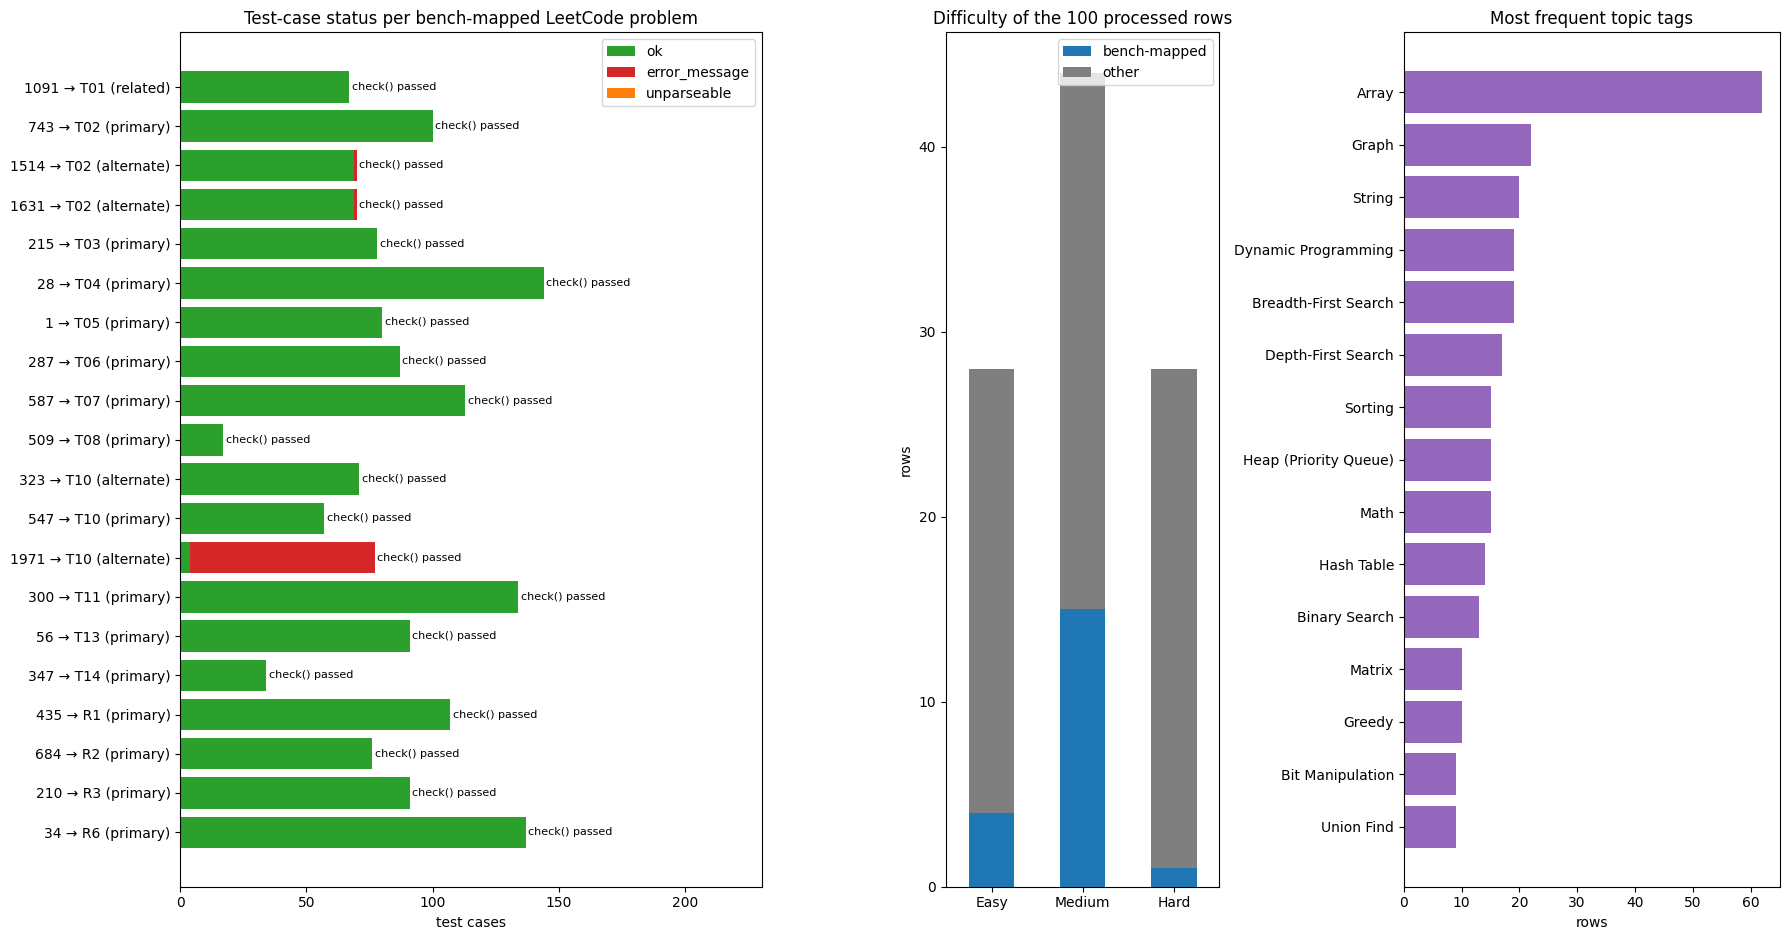

In [24]:
rows = []
for e in examples:
    if not e["metadata_bench_task"]:
        continue
    status = Counter(c["status"] for c in json.loads(e["metadata_test_cases_json"]))
    rows.append({
        "question_id": e["metadata_question_id"],
        "slug": e["metadata_task_slug"],
        "bench_task": e["metadata_bench_task"],
        "role": e["metadata_bench_role"],
        "difficulty": e["metadata_difficulty"],
        "cases": e["metadata_n_test_cases"],
        "ok": status["ok"],
        "error_message": status["expected_is_error_message"],
        "unparseable": status["unparseable"],
        "expected_null": e["metadata_n_expected_null"],
        "reference_passes": e["metadata_reference_passes_check"],
    })
rows.sort(key=lambda r: (list(BENCH_TASKS).index(r["bench_task"]), r["question_id"]))  # T01..T14, then R1..R6
seeds = pd.DataFrame(rows)
print(f"{len(examples)} examples built, {len(seeds)} of them bench-mapped: {seeds.ok.sum()} parsed test cases, "
      f"{seeds.error_message.sum()} error-message outputs, {seeds.unparseable.sum()} unparseable, "
      f"{seeds.expected_null.sum()} expecting null; reference passes check(): "
      f"{seeds.reference_passes.eq(True).sum()}/{len(seeds)}")
display(seeds)

fig, axes = plt.subplots(1, 3, figsize=(18, max(4.5, 0.4 * len(seeds) + 1.5)),
                         gridspec_kw={"width_ratios": [1.7, 0.8, 1.1]})

# Left: stacked test-case statuses of every bench-mapped problem, with its reference-check result
ax = axes[0]
labels = [f"{s.question_id} → {s.bench_task.split('_')[0]} ({s.role.split('_')[0]})" for s in seeds.itertuples()]
left = pd.Series(0, index=seeds.index)
for col, colour in (("ok", "tab:green"), ("error_message", "tab:red"), ("unparseable", "tab:orange")):
    ax.barh(labels, seeds[col], left=left, color=colour, label=col)
    left = left + seeds[col]
for y, (total, passed) in enumerate(zip(left, seeds.reference_passes)):
    ax.text(total + 1, y, {True: "check() passed", False: "check() FAILED"}.get(passed, "not checked"),
            va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, left.max() * 1.6)
ax.set_xlabel("test cases")
ax.set_title("Test-case status per bench-mapped LeetCode problem")
ax.legend(loc="upper right")

# Middle: difficulty of all processed rows, bench-mapped or not
difficulty = pd.crosstab([e["metadata_difficulty"] for e in examples],
                         ["bench-mapped" if e["metadata_bench_task"] else "other" for e in examples])
difficulty.reindex(["Easy", "Medium", "Hard"], fill_value=0).plot.bar(
    stacked=True, ax=axes[1], rot=0, color={"bench-mapped": "tab:blue", "other": "tab:gray"})
axes[1].set_title(f"Difficulty of the {len(examples)} processed rows")
axes[1].set_xlabel("")
axes[1].set_ylabel("rows")
axes[1].legend(title=None)

# Right: the most frequent LeetCode topic tags among the processed rows
tags = Counter(t for e in examples for t in e["metadata_tags"]).most_common(15)
axes[2].barh([t for t, _ in tags], [n for _, n in tags], color="tab:purple")
axes[2].invert_yaxis()
axes[2].set_title("Most frequent topic tags")
axes[2].set_xlabel("rows")
plt.tight_layout()
plt.show()